# M05-4 | Mixed Precision: Keep Sensitive Layers in fp32 and See How Much Accuracy Recovers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m05_ptq_pipeline/04_mixed_precision.ipynb)

The layerwise SQNR in M05-3 gave clues. This notebook tests the clues by experiment: actually exclude a module from quantization and measure how much the overall output SQNR recovers.

- **A.** Write a Quantizer that "excludes some modules", wrapping XNNPACKQuantizer.
- **B.** Exclude each module one at a time and compare the overall SQNR.
- **C.** Remove only `fc`'s output quantization, to verify where B's result comes from.
- **D.** Error accumulates: quantize only the first k modules, and the larger k is, the lower the overall SQNR.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # lets the notebook import this course's common/
    os.chdir(f"{repo}/en/m05_ptq_pipeline")

In [2]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate, make_loader, trained_tiny_net
from common.graph_utils import qdq_nodes, sqnr
from common.models import example_inputs
from common.pt2e import (
    ANNOTATION_KEY,
    QuantizationAnnotation,
    Quantizer,
    convert_pt2e,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, MUTED = "#2a78d6", "#52514e"

## A. A Quantizer That Excludes Some Modules

`SkipQuantizer` first lets the inner XNNPACKQuantizer annotate as usual, then clears the annotations of nodes inside the specified modules, so those nodes stay in fp32 (the partial quantization of M03-6).
To tell which module a node belongs to, look at its `node.meta["nn_module_stack"]`.

Clearing annotations has a catch: another node's annotation may be a `SharedQuantizationSpec` pointing to a node that was cleared (M03-4). If not handled, `prepare_pt2e` raises a `KeyError`.
And once the pointed-to annotation is cleared, the annotations pointing to **it** become invalid too, so clearing has to repeat until nothing changes.

`no_output` is used in section C: it removes only the output quantization of those modules, while inputs and weights are still quantized.

In [3]:
def in_module(node, name):
    """Whether node belongs to module `name` (including submodules)."""
    stack = node.meta.get("nn_module_stack") or {}
    return any(path == name or path.startswith(name + ".") for path, _ in stack.values())


def shares_with(spec, dead):
    """Whether spec shares with a node whose annotation has been cleared."""
    if type(spec).__name__ != "SharedQuantizationSpec":
        return False
    target = spec.edge_or_node
    return (target[0] if isinstance(target, tuple) else target) in dead


class SkipQuantizer(Quantizer):
    def __init__(self, inner, skip=(), no_output=()):
        self.inner, self.skip, self.no_output = inner, tuple(skip), tuple(no_output)

    def annotate(self, model):
        self.inner.annotate(model)
        dead = set()  # nodes whose output is no longer quantized
        for n in model.graph.nodes:
            ann = n.meta.get(ANNOTATION_KEY)
            if n.op != "call_function" or ann is None:
                continue
            if any(in_module(n, m) for m in self.skip):
                n.meta[ANNOTATION_KEY] = QuantizationAnnotation(_annotated=True)  # clear everything but still mark as processed
                dead.add(n)
            elif any(in_module(n, m) for m in self.no_output):
                ann.output_qspec = None
                dead.add(n)
        changed = True
        while changed:  # invalidated sharing cascades: keep clearing until nothing changes
            changed = False
            for n in model.graph.nodes:
                ann = n.meta.get(ANNOTATION_KEY)
                if ann is None:
                    continue
                for edge in [e for e, spec in ann.input_qspec_map.items() if shares_with(spec, dead)]:
                    del ann.input_qspec_map[edge]
                    changed = True
                if n not in dead and shares_with(ann.output_qspec, dead):
                    ann.output_qspec = None
                    dead.add(n)
                    changed = True
        return model

    def validate(self, model):
        pass

Model, calibration data, and evaluation data are all the same as in M05-1:

In [4]:
model = trained_tiny_net()
gm = export_module(model, example_inputs())
test_loader = make_loader(n=1024, seed=2, shuffle=False)
(x,) = next(calibration_batches(64, seed=9))
with torch.no_grad():
    y_ref = model(x)


def quantize(**skip_kwargs):
    prepared = prepare_pt2e(copy.deepcopy(gm), SkipQuantizer(get_xnnpack_quantizer(is_per_channel=True)[0], **skip_kwargs))
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return convert_pt2e(prepared)


def measure(converted):
    with torch.no_grad():
        return sqnr(y_ref, converted(x)), evaluate(converted, test_loader), len(qdq_nodes(converted))


def show(results):
    return table([[k, f"{s:.2f}", f"{a:.4f}", q] for k, (s, a, q) in results.items()],
                 ["setting", "output SQNR (dB)", "accuracy", "# q/dq"])

## B. Exclude Each Module One at a Time

The four submodules of `TinyConvNet` are, in order, `stem`, `block`, `head_conv`, and `fc`. Each time, keep just one of them in fp32 and quantize the rest to int8 as usual:

In [5]:
MODULES = ("stem", "block", "head_conv", "fc")
b = {"all int8": measure(quantize())}
for name in MODULES:
    b[f"{name} in fp32"] = measure(quantize(skip=[name]))
show(b)

setting,output SQNR (dB),accuracy,# q/dq
all int8,27.32,0.7051,28
stem in fp32,27.68,0.7080,23
block in fp32,26.84,0.7100,19
head_conv in fp32,27.19,0.7051,23
fc in fp32,33.17,0.7041,25


In [6]:
base = b["all int8"][0]
gain = {name: b[f"{name} in fp32"][0] - base for name in MODULES}
best = max(gain, key=lambda k: gain[k])
print("SQNR change after exclusion:", {k: f"{v:+.2f} dB" for k, v in gain.items()})
assert best == "fc" and abs(gain["head_conv"]) < 1.0
assert all(b[f"{n} in fp32"][2] < b["all int8"][2] for n in MODULES)

SQNR change after exclusion: {'stem': '+0.36 dB', 'block': '-0.48 dB', 'head_conv': '-0.13 dB', 'fc': '+5.85 dB'}


- **Excluding `fc` recovers the most**; `head_conv`, which dropped the most in the M05-3 layerwise table, barely changes when excluded. The location where layerwise SQNR drops a lot is not necessarily the most useful one to exclude.
- After excluding a module the q/dq count goes down (one less layer quantized means one less layer's quantization points), but there are still q/dq at the boundary between fp32 and int8 (M03-6).
- Accuracy is insensitive on this task (M05-1); the differences are at the noise level, and only SQNR shows them.

## C. Why Excluding fc Works

When `fc` is kept in fp32, its input, weight, and output are all unquantized. Try removing only its **output** quantization (input and weight stay int8):

In [7]:
c = {"all int8": b["all int8"], "fc in fp32 (input, weight, output all unquantized)": b["fc in fp32"],
     "fc output quantization removed (input, weight still int8)": measure(quantize(no_output=["fc"]))}
show(c)

setting,output SQNR (dB),accuracy,# q/dq
all int8,27.32,0.7051,28
"fc in fp32 (input, weight, output all unquantized)",33.17,0.7041,25
"fc output quantization removed (input, weight still int8)",33.22,0.7041,26


In [8]:
only_output = c["fc output quantization removed (input, weight still int8)"][0]
print(f"output quantization removed only: {only_output:.2f} dB; whole fc in fp32: {b['fc in fp32'][0]:.2f} dB")
assert abs(only_output - b["fc in fp32"][0]) < 0.5

output quantization removed only: 33.22 dB; whole fc in fp32: 33.17 dB


Removing only `fc`'s output quantization brings SQNR back to about the same as "the whole `fc` in fp32": nearly all the benefit of excluding `fc` in section B comes from **the final output (logits) no longer being quantized**.
Why this model's logits are so sensitive to quantization is not investigated here (possibly related to the logits' value range, an inference); whether other models behave the same is not verified.

> This matches practical experience: it usually works best to keep the head and tail of a model at higher precision; the blog post "[Learning Zero-Point and Scale in Quantization Parameters](https://bobondemon.github.io/2022/12/04/Learning-Zero-Point-and-Scale-in-Quantization-Parameters/#%E4%B8%80%E4%BA%9B%E8%A8%93%E7%B7%B4%E8%AA%AA%E6%98%8E)" (in Chinese) also mentions that LSQ keeping the first and last layers at 8 bit is already standard practice.

The mixed precision workflow is therefore: use the overall SQNR to tell whether there is a problem → narrow down with layerwise SQNR (M05-3) → confirm candidates by excluding them experimentally (this section) → among the fixes that solve the problem, pick the least invasive one.
Here the least invasive is removing only `fc`'s output quantization. "Less invasive is cheaper" is an inference; execution cost is not measured here.

## D. Error Accumulates: Quantize Only the First k Modules

Quantize the first k modules and keep the rest in fp32. k goes from 1 to 4:

In [9]:
d = []
for k in range(1, len(MODULES) + 1):
    d.append((" + ".join(MODULES[:k]), measure(quantize(skip=MODULES[k:]))[0]))

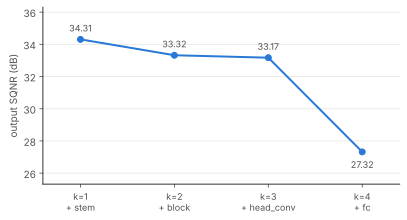

In [10]:
#| code-fold: true
#| code-summary: Plotting code
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(range(len(d)), [s for _, s in d], color=BLUE, lw=2, marker="o", ms=6)
for i, (_, s) in enumerate(d):
    below = i == len(d) - 1  # the last point is at the end of a descending segment; put its label below so it doesn't overlap the line
    ax.annotate(f"{s:.2f}", (i, s), xytext=(0, -16 if below else 8), textcoords="offset points", ha="center",
                color=MUTED, fontsize=9)
ax.set_xticks(range(len(d)), [f"k={k + 1}\n+ {name.split(' + ')[-1]}" for k, (name, _) in enumerate(d)], fontsize=9)
ax.set_xlim(-0.4, len(d) - 0.6)
ax.set_ylim(min(s for _, s in d) - 2, max(s for _, s in d) + 2)
ax.set_ylabel("output SQNR (dB)", color=MUTED)
ax.grid(axis="y", color="#e6e5e1", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [11]:
steps = [d[i][1] - d[i - 1][1] for i in range(1, len(d))]
table([[k + 1, name, f"{s:.2f}", "—" if k == 0 else f"{steps[k - 1]:+.2f}"] for k, (name, s) in enumerate(d)],
      ["k", "int8 modules", "output SQNR (dB)", "vs previous row"])

k,int8 modules,output SQNR (dB),vs previous row
1,stem,34.31,—
2,stem + block,33.32,-0.98
3,stem + block + head_conv,33.17,-0.15
4,stem + block + head_conv + fc,27.32,-5.85


In [12]:
assert all(step < 0 for step in steps)  # monotonically decreasing
assert min(steps) == steps[-1]  # adding fc drops the most

The x axis of the plot labels the module newly quantized at step k.

- The more modules are quantized, the more the overall SQNR drops monotonically: quantization error accumulates along the network, which is why M05-3 saw "lower toward the output".
- But the cost of adding each module is uneven: adding `fc` drops the most in one go (section C: nearly all from the output quantization of the logits). On this model it is not that every layer contributes a similar amount of error that then adds up, but that a few locations dominate.

Error does accumulate, but to find the problem you have to exclude candidates one by one experimentally; the trend of the layerwise scores alone isn't enough.

## Summary

- A Quantizer that excludes some modules has to handle shared annotations: clear repeatedly until nothing changes.
- The location with the largest layerwise SQNR drop is not necessarily useful to exclude; what this model is really sensitive to is the output quantization of the logits.
- Error accumulates along the network but is dominated by a few locations; narrow down first, then confirm by experiment.